# 01 EDA: CCPD2019 sample
Runs on Colab (Drive mounted). Data-prep logic lives in `src/alpr/ccpd.py`; plots and tables live here.
CCPD license: Zenodo says CC BY 4.0, original repo terms unchecked, so this notebook shows statistics and plots only, no sample images.

In [27]:
import os, shutil
import collections, tarfile
import pandas as pd
from pathlib import PurePosixPath
import os, shutil, tarfile
from collections import Counter
from pathlib import Path, PurePosixPath
import matplotlib.pyplot as plt
import re
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

In [28]:
# Parameters
SEED = 0
DRIVE = "/content/drive/MyDrive/alpr"
ARCHIVES = f"{DRIVE}/archives"
ARCHIVE = "/content/CCPD2019.tar.xz"        # local VM disk (fast)
SAMPLE_TAR = "/content/ccpd_sample.tar"     # built locally, copied to Drive at the end
MANIFEST = f"{ARCHIVES}/ccpd_manifest.csv"  # small file, stays on Drive
TRAIN_PER = 2200  # per subset (8 subsets); changing quotas needs no new archive pass: delete MANIFEST and rerun 4b
HELDOUT = 300      # total, spread evenly over subsets
LISTING_LOCAL = "/content/ccpd_listing.txt"          # full member listing, read by 4b when present
LISTING_DRIVE = f"{ARCHIVES}/ccpd_listing.txt"       # copy that survives a recycled VM
EXPECTED_SAMPLE_MD5 = "5019a5333b4a92aded34cd3fb52eff4c"  # recorded in PLAN.md
SAMPLE_DIR = "/content/ccpd_sample"                  # extracted sample on the VM
REPORTS = f"{DRIVE}/reports/eda"                     # PNGs are also written here
STATS_CSV = f"{REPORTS}/image_stats.csv"             # cache of the pixel pass (5f)

## Setup

In [29]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
%%bash
set -e
cd /content
if [ -d vehicle-plate-recognition ]; then git -C vehicle-plate-recognition pull --ff-only; else git clone https://github.com/medrees-1000/vehicle-plate-recognition.git; fi
pip install -q uv  # approved raw pip: only to bootstrap uv on Colab
uv pip install --system -q --no-deps -e /content/vehicle-plate-recognition

Already up to date.


In [31]:
import os, shutil
from alpr import ccpd  # ImportError on the first run? Restart the kernel once: an editable install is not visible to an already-running kernel.

os.makedirs(ARCHIVES, exist_ok=True)
print("alpr.ccpd:", ccpd.__file__)
print("local disk free GB:", round(shutil.disk_usage("/content").free / 1e9, 1))
print("Drive free GB:", round(shutil.disk_usage("/content/drive").free / 1e9, 1))
print("archive on Drive:", os.path.exists(ARCHIVE))

alpr.ccpd: /content/vehicle-plate-recognition/src/alpr/ccpd.py
local disk free GB: 97.8
Drive free GB: 92.9
archive on Drive: True


In [32]:
from alpr import ccpd

## Step 4: data prep
Each cell is safe to rerun: download resumes from the partial file (lost if the VM recycles) and verifies MD5, sample and build skip if their output exists (build writes to `.part` first). Keep the Colab session connected while they run.

In [33]:
# 4a. Download CCPD2019 (13.2 GB) to the VM's local disk and verify MD5
!python -u -m alpr.ccpd download "{ARCHIVE}"

/content/CCPD2019.tar.xz exists (13.2 GB), checking MD5...
/content/CCPD2019.tar.xz: MD5 ok (0dfbca0e6fcb7cb8ea720b0eae94c735)


In [34]:
# 4b. Pass 1: list the archive once (cached), check the subfolders, draw the stratified sample
!python -u -m alpr.ccpd sample "{ARCHIVE}" "{MANIFEST}" --seed {SEED} --train-per {TRAIN_PER} --heldout {HELDOUT} --cache "{LISTING_LOCAL}" "{LISTING_DRIVE}"

/content/drive/MyDrive/alpr/archives/ccpd_manifest.csv exists, skipping


In [35]:
# 4c. Pass 2: stream the archive again, copy only the sampled images into one local .tar (+ manifest.csv); the last cell copies the sample to Drive (the archive copy is optional)
!python -u -m alpr.ccpd build "{ARCHIVE}" "{MANIFEST}" "{SAMPLE_TAR}"

/content/ccpd_sample.tar exists, skipping


In [36]:
# 4d. Verify the packed sample against the manifest
import collections, tarfile
rows = ccpd.read_manifest(MANIFEST)
with tarfile.open(SAMPLE_TAR) as tf:
    names = [n for n in tf.getnames() if n != "manifest.csv"]
print("manifest rows:", len(rows), "| images in tar:", len(names))
print("tar per split:", dict(collections.Counter(n.split("/")[0] for n in names)))
assert sorted(n.split("/", 1)[1] for n in names) == sorted(m.rsplit("/", 1)[1] for m, _, _ in rows)
print("sample tar:", round(os.path.getsize(SAMPLE_TAR) / 1e9, 2), "GB, MD5", ccpd.file_md5(SAMPLE_TAR))

manifest rows: 17900 | images in tar: 17900
tar per split: {'heldout': 300, 'train': 17600}
sample tar: 1.26 GB, MD5 5019a5333b4a92aded34cd3fb52eff4c


In [37]:
# !cp /content/ccpd_sample.tar {ARCHIVES}/ccpd_sample.tar
# !md5sum /content/ccpd_sample.tar {ARCHIVES}/ccpd_sample.tar

## EDA
Tables only, no sample images (CCPD license handling).

In [38]:
# 5a. Duplicates across subfolders, from the cached listing (no archive pass)
import pandas as pd
from pathlib import PurePosixPath

names = open(next(p for p in (LISTING_LOCAL, LISTING_DRIVE) if os.path.exists(p))).read().splitlines()
df = pd.DataFrame({"member": names})
df["subset"] = df.member.map(lambda n: PurePosixPath(n).parent.name)
df["base"] = df.member.map(lambda n: PurePosixPath(n).name)
per_name = df.groupby("base").agg(n_files=("member", "size"), n_subsets=("subset", "nunique"))
df["dup"] = df.base.map(per_name.n_files) > 1
print(f"{len(df):,} files, {len(per_name):,} unique names; names with >1 file: {(per_name.n_files > 1).sum():,} "
      f"({df.dup.sum():,} files, {df.dup.mean():.1%})")
print("\nShare of each subfolder's files in a duplicated name:")
print(df.groupby("subset").dup.mean().sort_values(ascending=False).map("{:.0%}".format).to_string())
print("\nNames by number of files (rows) and number of subfolders (columns):")
print(pd.crosstab(per_name.n_files, per_name.n_subsets))
present = pd.crosstab(df.base, df.subset).clip(upper=1)
print("\nNames shared by each pair of subfolders (diagonal = unique names in the subfolder):")
print((present.T @ present).to_string())

kept, removed = ccpd.dedup([n for n in names if PurePosixPath(n).parent.name != ccpd.EXCLUDED])
avail = pd.Series([PurePosixPath(n).parent.name for n in kept]).value_counts()
need = TRAIN_PER + HELDOUT // len(ccpd.SUBSETS) + 1
print(f"\nAfter dedup (np excluded): {len(kept):,} unique images, {removed:,} files collapsed.")
print(f"Available per subset label (need {need}):")
print(avail.reindex(ccpd.PRIORITY).to_string())

355,013 files, 313,518 unique names; names with >1 file: 34,917 (76,412 files, 21.5%)

Share of each subfolder's files in a duplicated name:
subset
ccpd_blur         72%
ccpd_db           67%
ccpd_fn           67%
ccpd_rotate       61%
ccpd_challenge    48%
ccpd_tilt         35%
ccpd_weather       1%
ccpd_base          0%
ccpd_np            0%

Names by number of files (rows) and number of subfolders (columns):
n_subsets       1      2     3    4   5   6
n_files                                    
1          278601      0     0    0   0   0
2               0  28989     0    0   0   0
3               0      0  5384    0   0   0
4               0      0     0  454   0   0
5               0      0     0    0  74   0
6               0      0     0    0   0  16

Names shared by each pair of subfolders (diagonal = unique names in the subfolder):
subset          ccpd_base  ccpd_blur  ccpd_challenge  ccpd_db  ccpd_fn  ccpd_np  ccpd_rotate  ccpd_tilt  ccpd_weather
subset                        

In [39]:
# 5b. Put the sample on the VM: copy if missing, check MD5, extract (safe to rerun)
import os, shutil, tarfile
from collections import Counter
from pathlib import Path, PurePosixPath

if not os.path.exists(SAMPLE_TAR):
    drive_tar = f"{ARCHIVES}/ccpd_sample.tar"
    if not os.path.exists(drive_tar):
        raise FileNotFoundError(f"sample tar not found locally ({SAMPLE_TAR}) or on Drive ({drive_tar}); run 4c first")
    print("copying the sample tar from Drive...")
    shutil.copyfile(drive_tar, SAMPLE_TAR)
got = ccpd.file_md5(SAMPLE_TAR)
if got != EXPECTED_SAMPLE_MD5:
    raise ValueError(f"sample tar MD5 is {got}, expected {EXPECTED_SAMPLE_MD5}: delete {SAMPLE_TAR} and rerun, or rebuild with 4c")
print("sample tar MD5 ok")

manifest = ccpd.read_manifest(MANIFEST)
count = lambda: sum(1 for _ in Path(SAMPLE_DIR).rglob("*.jpg"))
if count() != len(manifest):
    shutil.rmtree(SAMPLE_DIR, ignore_errors=True)  # a partial extraction: start clean
    with tarfile.open(SAMPLE_TAR) as tf:
        tf.extractall(SAMPLE_DIR, filter="data")
missing = [m for m, _, sp in manifest if not (Path(SAMPLE_DIR) / sp / PurePosixPath(m).name).exists()]
if count() != len(manifest) or missing:
    raise ValueError(f"extraction incomplete: {count()} jpgs found, {len(missing)} manifest images missing, manifest has {len(manifest)}")
print(f"{len(manifest):,} images in {SAMPLE_DIR}:", dict(Counter(sp for _, _, sp in manifest)))

sample tar MD5 ok
17,900 images in /content/ccpd_sample: {'heldout': 300, 'train': 17600}


In [40]:
# 5c. Metadata from filenames: the sample vs the deduplicated population (counts and tables only)
def save_fig(fig, name):
    os.makedirs(REPORTS, exist_ok=True)
    fig.savefig(f"{REPORTS}/{name}.png", dpi=150, bbox_inches="tight")

def parse_frame(members):
    recs, bad = [], 0
    for m in members:
        try:
            lab = ccpd.parse_name(m)
        except ValueError:
            bad += 1  # counted, never printed
            continue
        x1, y1, x2, y2 = lab.bbox
        recs.append((m, PurePosixPath(m).parent.name, PurePosixPath(m).name, lab.area, *lab.tilt, x1, y1, x2, y2, lab.brightness, lab.blur))
    df = pd.DataFrame(recs, columns=["member", "subset", "base", "area", "tilt_h", "tilt_v", "x1", "y1", "x2", "y2", "brightness", "blur"])
    df["bw"], df["bh"] = df.x2 - df.x1, df.y2 - df.y1
    return df, bad

manifest = ccpd.read_manifest(MANIFEST)
sample_df, bad = parse_frame([m for m, _, _ in manifest])
if bad:
    raise ValueError(f"{bad} sample names do not parse; the sample and ccpd.parse_name disagree")
sample_df["split"] = [sp for _, _, sp in manifest]
if list(sample_df.subset) != [s for _, s, _ in manifest]:
    raise ValueError("manifest subset labels differ from the member paths")

listing = next((p for p in (LISTING_LOCAL, LISTING_DRIVE) if os.path.exists(p)), None)
if listing is None:
    raise FileNotFoundError(f"no cached listing at {LISTING_LOCAL} or {LISTING_DRIVE}; rerun 4b")
names = open(listing).read().splitlines()
pool = [n for n in names if PurePosixPath(n).parent.name != ccpd.EXCLUDED]  # np first, as in ccpd.sample
pop_df, bad_pop = parse_frame(pool)
kept, collapsed = ccpd.dedup(list(pop_df.member))
pop_df = pop_df[pop_df.member.isin(set(kept))].reset_index(drop=True)
print(f"listing {len(names):,} names; np excluded {len(names) - len(pool):,}; unparseable {bad_pop:,}; "
      f"duplicate files collapsed {collapsed:,}; population {len(pop_df):,}")
if not sample_df.member.isin(set(pop_df.member)).all():
    raise ValueError("some sampled images are not in the deduplicated population: the dedup rule changed since the sample was built")

cols = ["area", "tilt_h", "tilt_v", "bw", "bh", "brightness", "blur"]
for title, d in (("Sample", sample_df), ("Population (deduplicated, np excluded)", pop_df)):
    print(f"\n{title}, n={len(d):,}")
    print(d[cols].describe().T[["mean", "std", "min", "50%", "max"]].round(1).to_string())

listing 355,013 names; np excluded 3,036; unparseable 0; duplicate files collapsed 41,495; population 310,482

Sample, n=17,900
                    mean           std   min    50%           max
area        3.306200e+10  1.130651e+11   1.0  363.0  9.967672e+11
tilt_h      2.030000e+01  2.860000e+01   0.0    9.0  1.270000e+02
tilt_v      2.220000e+01  2.690000e+01   0.0   12.0  1.160000e+02
bw          2.368000e+02  8.970000e+01  59.0  225.0  7.190000e+02
bh          1.225000e+02  5.570000e+01  25.0  111.0  5.210000e+02
brightness  9.840000e+01  4.610000e+01   6.0   97.0  2.420000e+02
blur        5.340000e+01  6.850000e+01   0.0   28.0  9.390000e+02

Population (deduplicated, np excluded), n=310,482
                    mean           std   min           50%           max
area        1.661287e+11  2.007183e+11   1.0  1.365302e+11  9.997605e+11
tilt_h      6.240000e+01  3.950000e+01   0.0  8.900000e+01  1.290000e+02
tilt_v      5.990000e+01  3.580000e+01   0.0  8.100000e+01  1.300000e+02
b

split           heldout  train  sampled  available  fraction
subset                                                      
ccpd_weather         37   2200     2237       9999     0.224
ccpd_rotate          37   2200     2237      10050     0.223
ccpd_db              38   2200     2238       9901     0.226
ccpd_blur            38   2200     2238      16629     0.135
ccpd_fn              37   2200     2237      16718     0.134
ccpd_tilt            37   2200     2237      21353     0.105
ccpd_challenge       38   2200     2238      25836     0.087
ccpd_base            38   2200     2238     199996     0.011


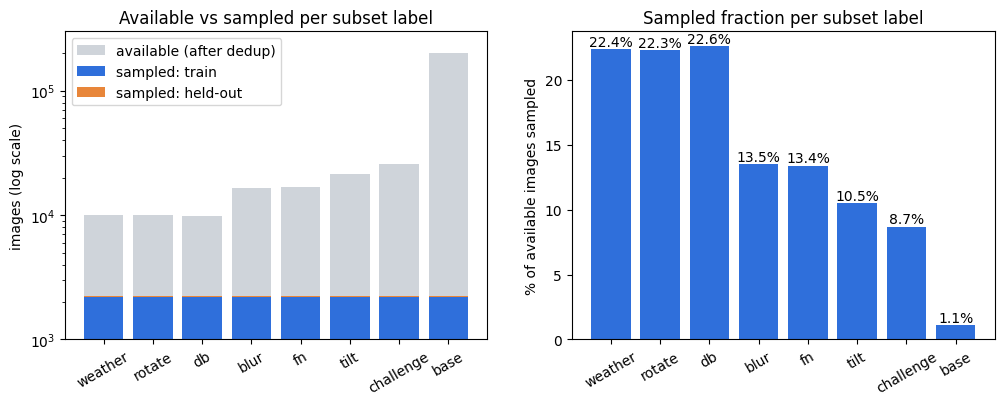


Sampled images by kept label (rows) and number of subfolders their name appears in (columns):
n_tags             1     2    3   4   5  6
subset                                    
ccpd_weather    2212    25    0   0   0  0
ccpd_rotate      891  1062  242  27  12  3
ccpd_db          748   864  530  87   9  0
ccpd_blur        805  1194  239   0   0  0
ccpd_fn          912  1320    5   0   0  0
ccpd_tilt       2062   175    0   0   0  0
ccpd_challenge  2238     0    0   0   0  0
ccpd_base       2238     0    0   0   0  0

Share of sampled images that also appear in another subfolder:
subset
ccpd_weather       1%
ccpd_rotate       60%
ccpd_db           67%
ccpd_blur         64%
ccpd_fn           59%
ccpd_tilt          8%
ccpd_challenge     0%
ccpd_base          0%


In [41]:
# 5d. Balance: available (after dedup) vs sampled per subset label, and how many subfolder tags each sampled image carries
try:
    sample_df, pop_df, names
except NameError:
    raise RuntimeError("run 5c first")

avail = pop_df.subset.value_counts().reindex(ccpd.PRIORITY)
tab = sample_df.groupby(["subset", "split"]).size().unstack(fill_value=0).reindex(ccpd.PRIORITY)
if (tab.train != TRAIN_PER).any() or tab.heldout.sum() != HELDOUT or tab.isna().any().any():
    raise ValueError(f"sample does not match TRAIN_PER={TRAIN_PER} / HELDOUT={HELDOUT}:\n{tab}")
tab["sampled"] = tab.train + tab.heldout
tab["available"] = avail
tab["fraction"] = (tab.sampled / tab.available).round(3)
print(tab.to_string())

x, labels = list(range(len(tab))), [s.replace("ccpd_", "") for s in tab.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(x, tab.available, color="#cfd4da", label="available (after dedup)")
ax1.bar(x, tab.train, color="#2f6fdb", label="sampled: train")
ax1.bar(x, tab.heldout, bottom=tab.train, color="#e8863a", label="sampled: held-out")
ax1.set_yscale("log"); ax1.set_ylim(1_000, tab.available.max() * 1.5)  # a log axis must start below the sampled counts (~2,200)
ax1.set_ylabel("images (log scale)"); ax1.set_title("Available vs sampled per subset label"); ax1.legend()
ax2.bar(x, tab.fraction * 100, color="#2f6fdb")
for i, v in enumerate(tab.fraction * 100):
    ax2.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
ax2.set_ylabel("% of available images sampled"); ax2.set_title("Sampled fraction per subset label")
for ax in (ax1, ax2):
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30)
save_fig(fig, "01_balance"); plt.show()

# subfolder tags per image, from the full listing (the label kept by dedup is only one of them)
all_df = pd.DataFrame({"base": [PurePosixPath(n).name for n in names], "subset": [PurePosixPath(n).parent.name for n in names]})
n_tags = all_df.groupby("base").subset.nunique()
sample_df["n_tags"] = sample_df.base.map(n_tags)
if sample_df.n_tags.isna().any():
    raise ValueError("some sampled names are missing from the listing")
print("\nSampled images by kept label (rows) and number of subfolders their name appears in (columns):")
print(pd.crosstab(sample_df.subset, sample_df.n_tags).reindex(ccpd.PRIORITY).to_string())
print("\nShare of sampled images that also appear in another subfolder:")
print((sample_df.n_tags > 1).groupby(sample_df.subset).mean().reindex(ccpd.PRIORITY).map("{:.0%}".format).to_string())


Population: median by subset label
                        area  tilt_h  tilt_v  brightness  blur     bw     bh
subset                                                                      
ccpd_weather    3.250000e+02     2.0     4.0        80.0  41.0  262.0  102.0
ccpd_rotate     4.240000e+02    22.0    12.0       115.0  68.0  208.0  170.0
ccpd_db         3.550000e+02     3.0     9.0        28.0  11.0  262.0  111.0
ccpd_blur       2.270000e+02     2.0     5.0        88.0   4.0  215.0   87.0
ccpd_fn         7.710000e+02     5.0    11.0       104.0  44.0  306.0  161.0
ccpd_tilt       4.250000e+02    21.0    32.0        94.0  73.0  207.0  167.0
ccpd_challenge  1.840000e+02     4.0     3.0       114.0  16.0  181.0   83.0
ccpd_base       2.098420e+11    90.0    87.0       113.0  37.0  245.0   91.0

Sample: median by subset label
                        area  tilt_h  tilt_v  brightness  blur     bw     bh
subset                                                                      
ccpd_wea

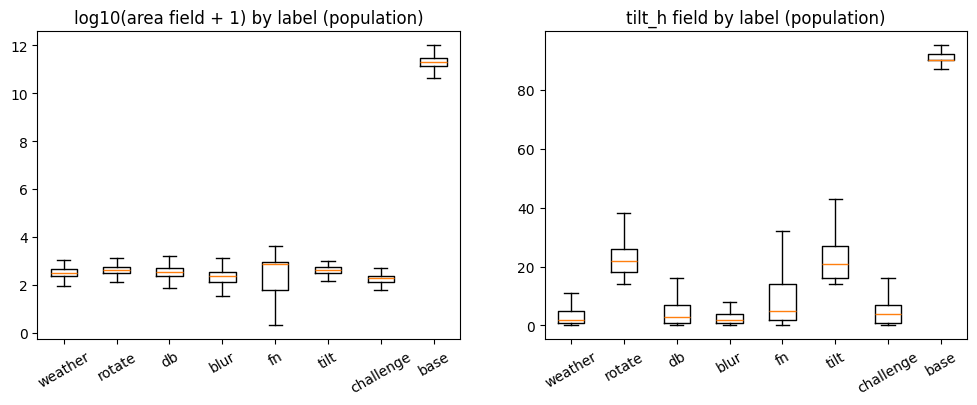

In [42]:
# 5e. Anomaly check: do the filename fields mean the same thing in every subset label? (counts and shapes only, no names)
try:
    sample_df, pop_df
except NameError:
    raise RuntimeError("run 5c first")

cols = ["area", "tilt_h", "tilt_v", "brightness", "blur", "bw", "bh"]
for title, d in (("Population", pop_df), ("Sample", sample_df)):
    print(f"\n{title}: median by subset label")
    print(d.groupby("subset")[cols].median().reindex(ccpd.PRIORITY).round(1).to_string())
print("\nPopulation: 5% / 50% / 95% of area and tilt_h by label")
print(pop_df.groupby("subset")[["area", "tilt_h"]].quantile([0.05, 0.5, 0.95]).unstack().reindex(ccpd.PRIORITY).round(1).to_string())
print("\nShare of population rows with area > 1,000,000, by label:")
print((pop_df.area > 1_000_000).groupby(pop_df.subset).mean().reindex(ccpd.PRIORITY).map("{:.0%}".format).to_string())

# field formats: digit runs are replaced by 9, so formats can be compared without printing any name
fields = pd.DataFrame([PurePosixPath(m).stem.split("-") for m in pop_df.member],
                      columns=["area", "tilt", "bbox", "verts", "plate", "brightness", "blur"])
fields["subset"] = pop_df.subset.values
def top(s, k=8):
    return s.where(s.isin(s.value_counts().index[:k]), "other")
print("\nPopulation: number of digits in the area field, by label")
print(pd.crosstab(fields.subset, fields.area.str.len()).reindex(ccpd.PRIORITY).to_string())
for f in ("tilt", "bbox", "verts", "plate"):
    print(f"\nPopulation: shape of the {f} field by label (digit runs -> 9)")
    print(pd.crosstab(fields.subset, top(fields[f].map(lambda v: re.sub(r"\d+", "9", v)))).reindex(ccpd.PRIORITY).to_string())

order = list(ccpd.PRIORITY)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([np.log10(pop_df.area[pop_df.subset == s] + 1) for s in order], showfliers=False)
axes[0].set_title("log10(area field + 1) by label (population)")
axes[1].boxplot([pop_df.tilt_h[pop_df.subset == s] for s in order], showfliers=False)
axes[1].set_title("tilt_h field by label (population)")
for ax in axes:
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([s.replace("ccpd_", "") for s in order], rotation=30)
save_fig(fig, "00_fields_by_label"); plt.show()

In [43]:
# 5f. Pixel pass over the extracted sample, cached on Drive: size, status, brightness, plate-crop blur, dHash, file MD5
def laplacian_var(g):
    lap = g[1:-1, 1:-1] * -4 + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return float(lap.var())

def dhash(gray):  # 64-bit difference hash: left > right on a 9x8 thumbnail
    px = np.asarray(gray.resize((9, 8), Image.LANCZOS), dtype=np.int16)
    return int("".join("1" if b else "0" for b in (px[:, 1:] > px[:, :-1]).ravel()), 2)

def measure(r):
    out = {"base": r.base, "status": "ok"}
    path = Path(SAMPLE_DIR) / r.split / r.base
    try:
        ccpd.check_image(path)  # filename parses, image opens, box inside image
        with Image.open(path) as im:
            w, h = im.size
            gray = im.convert("L")
        g = np.asarray(gray, dtype=np.float32)
        crop = g[r.y1:r.y2, r.x1:r.x2]
        out.update(w=w, h=h, img_brightness=float(g.mean()), crop_brightness=float(crop.mean()),
                   crop_blur=laplacian_var(crop) if min(crop.shape) >= 3 else np.nan,
                   dhash=format(dhash(gray), "016x"), md5=ccpd.file_md5(path))
    except (ValueError, OSError) as e:
        out["status"] = "bbox_outside" if "outside" in str(e) else type(e).__name__  # never the message: it holds the name
    return out

try:
    sample_df
except NameError:
    raise RuntimeError("run 5c first")
if os.path.exists(STATS_CSV):
    stats = pd.read_csv(STATS_CSV, dtype={"dhash": str, "md5": str})
    if len(stats) != len(sample_df) or set(stats.base) != set(sample_df.base):
        raise ValueError(f"{STATS_CSV} does not match the current sample: delete it and rerun")
    print(f"loaded cached pixel stats from {STATS_CSV}")
else:
    os.makedirs(REPORTS, exist_ok=True)
    stats = pd.DataFrame([measure(r) for r in tqdm(sample_df.itertuples(index=False), total=len(sample_df))])
    stats.to_csv(STATS_CSV + ".part", index=False)
    os.replace(STATS_CSV + ".part", STATS_CSV)
print(stats.status.value_counts().to_string())
if (stats.status != "ok").any():
    print(f"WARNING: {(stats.status != 'ok').sum()} images are not usable; later cells use the rest and 5i reports them")

loaded cached pixel stats from /content/drive/MyDrive/alpr/reports/eda/image_stats.csv
status
ok    17900


usable images: 17,900 of 17,900

Distinct image sizes (w, h): 1
w    h   
720  1160    17900

Plate box in the sample:
           mean     std     min      50%      max
bw      236.830  89.739  59.000  225.000  719.000
bh      122.530  55.712  25.000  111.000  521.000
frac      0.038   0.027   0.002    0.031    0.320
aspect    2.147   0.755   0.484    2.235    6.570
cx        0.504   0.085   0.114    0.501    0.860
cy        0.447   0.051   0.056    0.452    0.882

Median plate area fraction by subset label:
subset
ccpd_weather      0.0326
ccpd_rotate       0.0430
ccpd_db           0.0357
ccpd_blur         0.0228
ccpd_fn           0.0766
ccpd_tilt         0.0425
ccpd_challenge    0.0184
ccpd_base         0.0269


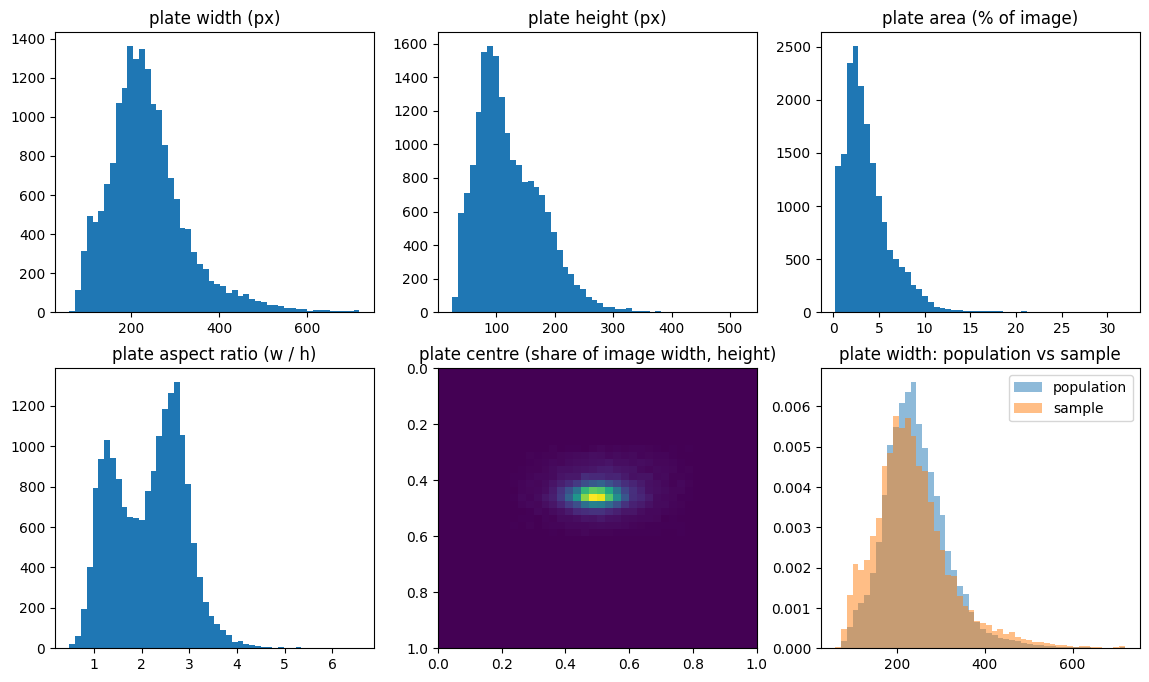

In [44]:
# 5g. Image sizes and plate bbox sizes (from the pixel pass)
try:
    stats
except NameError:
    raise RuntimeError("run 5f first")
full = sample_df.merge(stats, on="base", validate="one_to_one")
ok = full[full.status == "ok"].copy()
if ok.empty:
    raise ValueError("no usable images in the pixel stats")
print(f"usable images: {len(ok):,} of {len(full):,}")
sizes = ok.groupby(["w", "h"]).size().sort_values(ascending=False)
print(f"\nDistinct image sizes (w, h): {len(sizes)}")
print(sizes.head(10).to_string())

ok["frac"] = ok.bw * ok.bh / (ok.w * ok.h)
ok["aspect"] = ok.bw / ok.bh
ok["cx"], ok["cy"] = (ok.x1 + ok.x2) / 2 / ok.w, (ok.y1 + ok.y2) / 2 / ok.h
print("\nPlate box in the sample:")
print(ok[["bw", "bh", "frac", "aspect", "cx", "cy"]].describe().T[["mean", "std", "min", "50%", "max"]].round(3).to_string())
print("\nMedian plate area fraction by subset label:")
print(ok.groupby("subset").frac.median().reindex(ccpd.PRIORITY).round(4).to_string())

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes[0, 0].hist(ok.bw, bins=50); axes[0, 0].set_title("plate width (px)")
axes[0, 1].hist(ok.bh, bins=50); axes[0, 1].set_title("plate height (px)")
axes[0, 2].hist(ok.frac * 100, bins=50); axes[0, 2].set_title("plate area (% of image)")
axes[1, 0].hist(ok.aspect, bins=50); axes[1, 0].set_title("plate aspect ratio (w / h)")
axes[1, 1].hist2d(ok.cx, ok.cy, bins=40, range=[[0, 1], [0, 1]]); axes[1, 1].invert_yaxis()
axes[1, 1].set_title("plate centre (share of image width, height)")
axes[1, 2].hist(pop_df.bw, bins=50, density=True, alpha=0.5, label="population")
axes[1, 2].hist(sample_df.bw, bins=50, density=True, alpha=0.5, label="sample")
axes[1, 2].set_title("plate width: population vs sample"); axes[1, 2].legend()
save_fig(fig, "02_bbox"); plt.show()

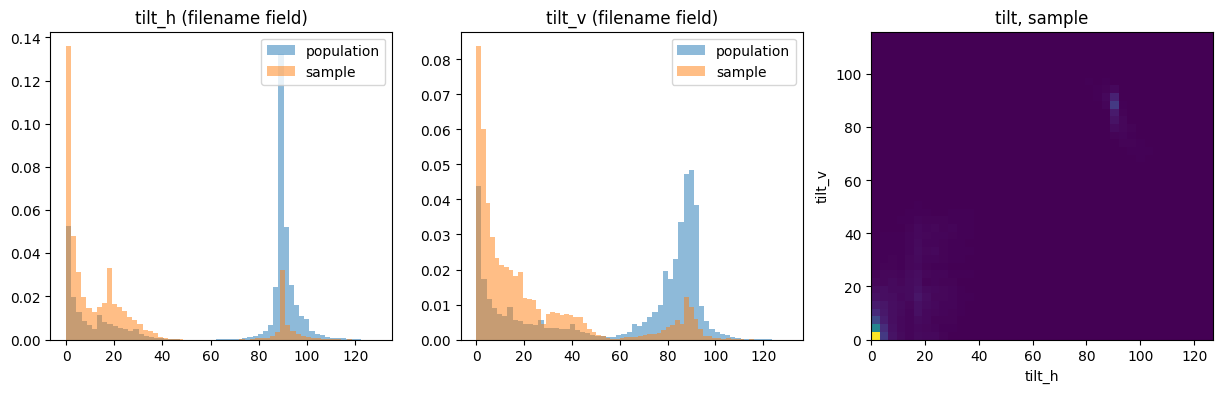

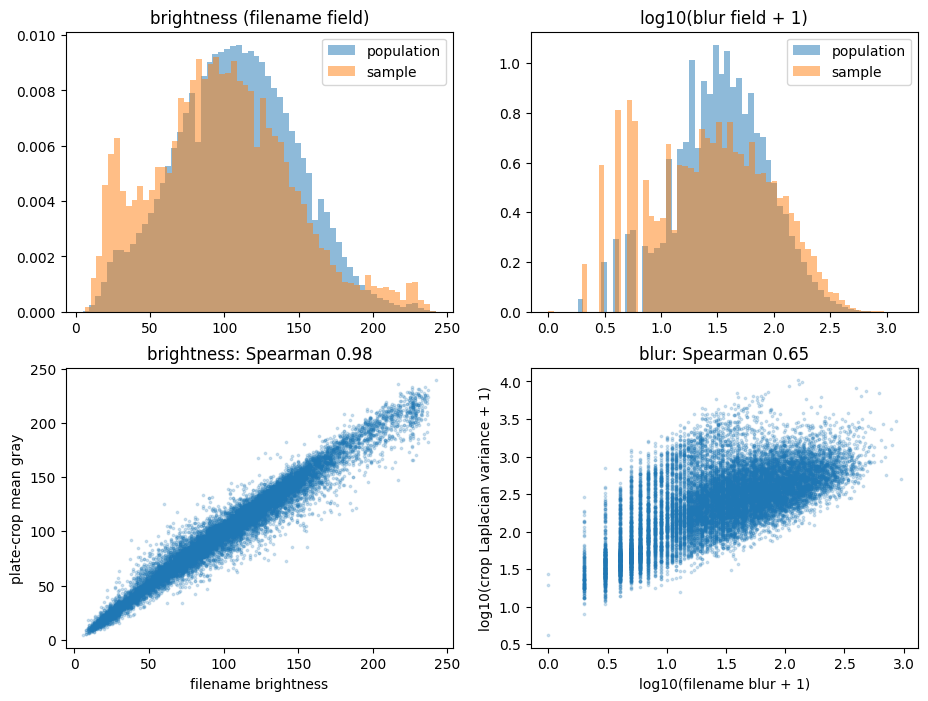

Train vs held-out: 5% / 50% / 95% of the filename fields
         area                      tilt_h             tilt_v             brightness              blur             
         0.05   0.50          0.95   0.05  0.50  0.95   0.05  0.50  0.95       0.05  0.50   0.95 0.05  0.50   0.95
split                                                                                                             
heldout  68.6  354.0  2.406088e+11    0.0  10.0  92.0    0.0  11.0  87.0       24.0  94.0  169.1  3.0  28.0  182.9
train    62.0  364.0  2.465733e+11    0.0   9.0  91.0    0.0  12.0  88.0       25.0  97.0  179.0  3.0  28.5  190.0

By subset label: Spearman of filename vs pixel, and the area field divided by the measured plate area fraction
                     n  rho_brightness  rho_blur  area_field/frac q25           q50           q75
ccpd_weather    2237.0            0.89      0.66         9.976000e+03  9.985630e+03  9.992980e+03
ccpd_rotate     2237.0            0.97      0.75         9.9

In [45]:
# 5h. Tilt, brightness and blur: filename fields (sample vs population, train vs held-out) and pixel-measured values
try:
    ok
except NameError:
    raise RuntimeError("run 5g first")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes[:2], ("tilt_h", "tilt_v")):
    ax.hist(pop_df[col], bins=60, density=True, alpha=0.5, label="population")
    ax.hist(sample_df[col], bins=60, density=True, alpha=0.5, label="sample")
    ax.set_title(f"{col} (filename field)"); ax.legend()
axes[2].hist2d(sample_df.tilt_h, sample_df.tilt_v, bins=40)
axes[2].set_xlabel("tilt_h"); axes[2].set_ylabel("tilt_v"); axes[2].set_title("tilt, sample")
save_fig(fig, "03_tilt"); plt.show()

rho = lambda a, b: a.rank().corr(b.rank())  # Spearman
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(pop_df.brightness, bins=60, density=True, alpha=0.5, label="population")
axes[0, 0].hist(sample_df.brightness, bins=60, density=True, alpha=0.5, label="sample")
axes[0, 0].set_title("brightness (filename field)"); axes[0, 0].legend()
axes[0, 1].hist(np.log10(pop_df.blur + 1), bins=60, density=True, alpha=0.5, label="population")
axes[0, 1].hist(np.log10(sample_df.blur + 1), bins=60, density=True, alpha=0.5, label="sample")
axes[0, 1].set_title("log10(blur field + 1)"); axes[0, 1].legend()
axes[1, 0].scatter(ok.brightness, ok.crop_brightness, s=3, alpha=0.2)
axes[1, 0].set_xlabel("filename brightness"); axes[1, 0].set_ylabel("plate-crop mean gray")
axes[1, 0].set_title(f"brightness: Spearman {rho(ok.brightness, ok.crop_brightness):.2f}")
axes[1, 1].scatter(np.log10(ok.blur + 1), np.log10(ok.crop_blur + 1), s=3, alpha=0.2)
axes[1, 1].set_xlabel("log10(filename blur + 1)"); axes[1, 1].set_ylabel("log10(crop Laplacian variance + 1)")
axes[1, 1].set_title(f"blur: Spearman {rho(ok.blur, ok.crop_blur):.2f}")
save_fig(fig, "04_brightness_blur"); plt.show()

print("Train vs held-out: 5% / 50% / 95% of the filename fields")
print(sample_df.groupby("split")[["area", "tilt_h", "tilt_v", "brightness", "blur"]].quantile([0.05, 0.5, 0.95]).unstack().round(1).to_string())

# does each filename field agree with the pixels in every subset label?
rows = {}
for s in ccpd.PRIORITY:
    d = ok[ok.subset == s]
    ratio = d.area / d.frac
    rows[s] = {"n": len(d), "rho_brightness": rho(d.brightness, d.crop_brightness), "rho_blur": rho(d.blur, d.crop_blur),
               "area_field/frac q25": ratio.quantile(0.25), "q50": ratio.quantile(0.5), "q75": ratio.quantile(0.75)}
print("\nBy subset label: Spearman of filename vs pixel, and the area field divided by the measured plate area fraction")
print(pd.DataFrame(rows).T.round(2).to_string())

In [46]:
# 5i. Label sanity (counts only: no names, no plate strings)
try:
    ok
except NameError:
    raise RuntimeError("run 5g first")
print("Image / label status:")
print(full.status.value_counts().to_string())

dev = []  # largest gap between the box and the bounding rectangle of the 4 vertices, as a share of the box's longer side
for m in ok.member:
    lab = ccpd.parse_name(m)
    xs, ys = [v[0] for v in lab.vertices], [v[1] for v in lab.vertices]
    x1, y1, x2, y2 = lab.bbox
    dev.append(max(abs(min(xs) - x1), abs(min(ys) - y1), abs(max(xs) - x2), abs(max(ys) - y2)) / max(x2 - x1, y2 - y1))
ok["vert_dev"] = dev
print("\nBox vs vertices (share of the longer box side): quantiles")
print(ok.vert_dev.quantile([0.5, 0.9, 0.99, 1.0]).round(3).to_string())
print("Images with a gap above 10%, by label:")
print((ok.vert_dev > 0.1).groupby(ok.subset).sum().reindex(ccpd.PRIORITY).to_string())

print("\nRanges of the filename fields (sample):")
print(sample_df[["area", "tilt_h", "tilt_v", "brightness", "blur"]].agg(["min", "max"]).T.to_string())

plates = pd.Series([ccpd.parse_name(m).plate for m in sample_df.member], index=sample_df.index)  # never printed
held = sample_df.split == "heldout"
print(f"\nPlates: {plates.nunique():,} distinct in {len(plates):,} images; most images of one plate: {plates.value_counts().iloc[0]}")
print(f"Held-out images whose plate also occurs in train: {plates[held].isin(set(plates[~held])).sum()} of {held.sum()}")
print("Most common first characters (province) and second characters (letter):")
print(Counter(p[0] for p in plates).most_common(8))
print(Counter(p[1] for p in plates).most_common(8))

Image / label status:
status
ok    17900

Box vs vertices (share of the longer box side): quantiles
0.50    0.000
0.90    0.033
0.99    0.082
1.00    0.138
Images with a gap above 10%, by label:
subset
ccpd_weather       0
ccpd_rotate        0
ccpd_db            0
ccpd_blur          0
ccpd_fn            0
ccpd_tilt          0
ccpd_challenge     0
ccpd_base         47

Ranges of the filename fields (sample):
            min           max
area          1  996767241379
tilt_h        0           127
tilt_v        0           116
brightness    6           242
blur          0           939

Plates: 17,311 distinct in 17,900 images; most images of one plate: 5
Held-out images whose plate also occurs in train: 16 of 300
Most common first characters (province) and second characters (letter):
[('皖', 16038), ('苏', 482), ('浙', 251), ('沪', 106), ('粤', 101), ('鲁', 93), ('豫', 90), ('鄂', 87)]
[('A', 15391), ('N', 308), ('B', 269), ('C', 245), ('D', 207), ('E', 196), ('H', 191), ('K', 169)]


Exact duplicates: 8 files in 4 groups; groups spanning train and held-out: 0

Near duplicates (Hamming <= 6): 162 pairs; images with at least one: 131 (0.7%)
Held-out images with a near duplicate in train: 5 of 300
Nearest-neighbour Hamming distance, quantiles:
0.01     7.0
0.05    10.0
0.25    13.0
0.50    14.0


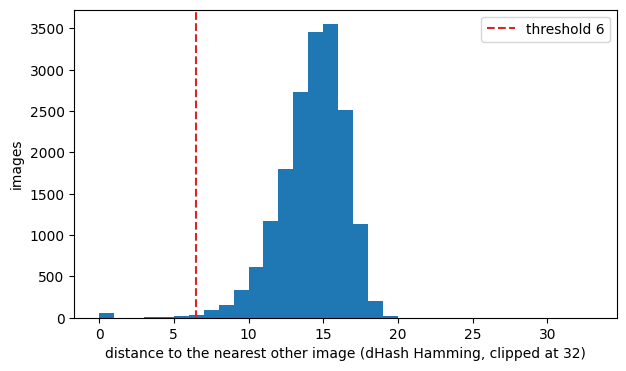

In [47]:
# 5j. Duplicates inside the sample: exact (file MD5) and near (dHash, Hamming <= 6). Counts only.
try:
    ok
except NameError:
    raise RuntimeError("run 5g first")
ok = ok.reset_index(drop=True)
split = ok.split.to_numpy()

dup = ok[ok.md5.duplicated(keep=False)]
print(f"Exact duplicates: {len(dup)} files in {dup.md5.nunique()} groups; groups spanning train and held-out: "
      f"{(dup.groupby('md5').split.nunique() > 1).sum()}")

h = np.array([int(x, 16) for x in ok.dhash], dtype=np.uint64)
if hasattr(np, "bitwise_count"):
    popcount = np.bitwise_count  # numpy >= 2
else:
    table = np.array([bin(i).count("1") for i in range(1 << 16)], dtype=np.uint8)
    popcount = lambda x: sum(table[((x >> np.uint64(s)) & np.uint64(0xFFFF)).astype(np.intp)] for s in (0, 16, 32, 48))
n, pairs, nn, hit = len(h), 0, [], np.zeros(len(h), bool)
for s in range(0, n, 500):
    blk = h[s:s + 500]
    d = popcount(blk[:, None] ^ h[None, :])
    d[np.arange(len(blk)), s + np.arange(len(blk))] = 255  # ignore self
    nn.append(d.min(axis=1))
    close = d <= 6
    pairs += int(close.sum())
    hit[s:s + len(blk)] |= (close & (split[None, :] != split[s:s + len(blk), None])).any(axis=1)
nn = np.concatenate(nn)
held = split == "heldout"
print(f"\nNear duplicates (Hamming <= 6): {pairs // 2:,} pairs; images with at least one: {(nn <= 6).sum():,} ({(nn <= 6).mean():.1%})")
print(f"Held-out images with a near duplicate in train: {(hit & held).sum()} of {held.sum()}")
print("Nearest-neighbour Hamming distance, quantiles:")
print(pd.Series(nn).quantile([0.01, 0.05, 0.25, 0.5]).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.clip(nn, 0, 32), bins=33, range=(0, 33)); ax.axvline(6.5, color="#d62728", ls="--", label="threshold 6")
ax.set_xlabel("distance to the nearest other image (dHash Hamming, clipped at 32)"); ax.set_ylabel("images"); ax.legend()
save_fig(fig, "05_duplicates"); plt.show()